# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 2 = GO / Gate 3 = NA the manifold is non-branching, so the
branching-only correlation and modules notebooks are not produced — this unconditional
expression notebook follows signatures directly.)*

Per the **derive-don't-inherit** mandate we do not inherit Puram's SNAI1/ZEB1 pair. We score a
candidate EMT-TF panel — the canonical Snail/Zeb/Twist factors **plus the mesenchymal
FOXC and PRRX factors** — along *this* trajectory and let the data choose the most end-specific
factor at each end (detection-gated). Deliverable: `expression.pdf`.

In [2]:
import os, sys, glob, re, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [3]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the rooted, signature-scored manifold

In [5]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime', round(t.min(),2), '->', round(t.max(),2))

cells: 65802 | pseudotime 0.0 -> 17.28


### Derive the end-specific EMT-TFs (data-driven)
For each candidate TF: fraction expressing, mean in the early (root) vs late (terminus)
pseudotime tercile, and Spearman correlation with pseudotime. Most negative rho (above a 3%
expression floor) marks the root end; most positive marks the terminus.

In [7]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t']).sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t
 FOXC1      0.024       0.015      0.002    -0.096
  ZEB2      0.177       0.147      0.101    -0.081
 SNAI1      0.027       0.018      0.005    -0.079
 FOXC2      0.012       0.004      0.002    -0.026
 SNAI2      0.086       0.020      0.008     0.004
 PRRX2      0.032       0.002      0.001     0.018
TWIST2      0.042       0.002      0.001     0.027
TWIST1      0.029       0.001      0.001     0.030
  ZEB1      0.135       0.051      0.076     0.055
 PRRX1      0.138       0.014      0.028     0.077

derived pair: ZEB2 (early/root) <-> PRRX1 (late/terminus)


### EMT-TF expression overlay (deliverable)
House categorical style: `figsize=(3.5,1.5)`, pseudotime left→right, `size=8`. Each factor is
thresholded at the upper quartile of expression among its expressing cells and drawn as a
coloured overlay on a grey manifold (early = blue, late = red); the more abundant marker is
drawn first so the sparser one reads on top.

ZEB2: 17.7% expressing; 2912 shown (upper quartile), mean pseudotime of shown = 0.44 (all = 0.50)
PRRX1: 13.8% expressing; 2267 shown (upper quartile), mean pseudotime of shown = 0.53 (all = 0.50)
saved expression.pdf


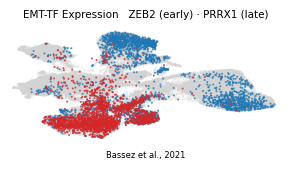

In [9]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=8, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=8, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) · {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Bassez et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown = {tn[m].mean():.2f} (all = {tn.mean():.2f})')
print('saved expression.pdf')